<a href="https://colab.research.google.com/github/leovarconrenno/Estacao-de-Reabastecimento-de-Hidrogenio---SCADA-Core/blob/main/etapa-03-arvores/Aula%2023%20-%20Protocolo%20de%20%C3%81rvore%20Geradora%20(STP%20RSTP)%20-%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 23 - Notebook: Simulação RSTP (IEEE 802.1w) na Rede SCADA H₂

Este notebook modela a rede Ethernet industrial em anel da Estação de Reabastecimento de Hidrogênio (`SW-SCADA`, `SW-S100`, `SW-S200`, `SW-S300`, `SW-SIS`), executa a convergência **RSTP** e valida o *failover* automático após rompimento do *backbone* principal.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pandas as pd
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

G = nx.Graph()
switches = {
    "SW-SCADA": {"prio": 4096,  "mac": "00:1A:2B:00:00:01", "zona": "Sala de Controle SCADA-Core"},
    "SW-S100":  {"prio": 8192,  "mac": "00:1A:2B:00:01:00", "zona": "Setor 100 (SUP-100, TK-101..103, XV-104)"},
    "SW-S200":  {"prio": 32768, "mac": "00:1A:2B:00:02:00", "zona": "Setor 200 (HEX-201, M-201)"},
    "SW-S300":  {"prio": 32768, "mac": "00:1A:2B:00:03:00", "zona": "Setor 300 (DISP-300, COM-301, BV-301)"},
    "SW-SIS":   {"prio": 32768, "mac": "00:1A:2B:00:04:00", "zona": "Painel SIS (ESD-100, AT-101..301)"},
}
for sw, attrs in switches.items():
    G.add_node(sw, **attrs)

enlaces = [
    ("SW-SCADA", "SW-S100", 2000,   "10 Gbps Fibra"),
    ("SW-SCADA", "SW-SIS",  20000,  "1 Gbps Fibra"),
    ("SW-S100",  "SW-S200", 20000,  "1 Gbps Fibra"),
    ("SW-S200",  "SW-S300", 20000,  "1 Gbps Fibra"),
    ("SW-S300",  "SW-SIS",  20000,  "1 Gbps Fibra"),
    ("SW-S100",  "SW-SIS",  200000, "100 Mbps Backup"),
]
for u, v, cost, desc in enlaces:
    G.add_edge(u, v, cost=cost, desc=desc)

print(f"Rede física HRS carregada: {G.number_of_nodes()} switches, {G.number_of_edges()} enlaces.")

Rede física HRS carregada: 5 switches, 6 enlaces.


In [2]:
def executar_rstp(grafo: nx.Graph):
    root = min(grafo.nodes, key=lambda n: (grafo.nodes[n]["prio"], grafo.nodes[n]["mac"]))
    dist = {n: float("inf") for n in grafo.nodes}
    parent = {n: None for n in grafo.nodes}
    dist[root] = 0
    nao_visitados = set(grafo.nodes)

    while nao_visitados:
        u = min(nao_visitados, key=lambda n: (dist[n], grafo.nodes[n]["prio"], grafo.nodes[n]["mac"]))
        nao_visitados.remove(u)
        if dist[u] == float("inf"):
            break
        for v in grafo.neighbors(u):
            alt = dist[u] + grafo[u][v]["cost"]
            if alt < dist[v]:
                dist[v] = alt
                parent[v] = u
            elif alt == dist[v] and parent[v] is not None:
                bid_u = (grafo.nodes[u]["prio"], grafo.nodes[u]["mac"])
                bid_p = (grafo.nodes[parent[v]]["prio"], grafo.nodes[parent[v]]["mac"])
                if bid_u < bid_p:
                    parent[v] = u

    ativas = [tuple(sorted((n, p))) for n, p in parent.items() if p is not None]
    set_ativas = set(ativas)
    bloqueadas = [tuple(sorted((u, v))) for u, v in grafo.edges if tuple(sorted((u, v))) not in set_ativas]

    linhas = []
    for u, v in grafo.edges:
        chave = tuple(sorted((u, v)))
        custo = grafo[u][v]["cost"]
        if chave in set_ativas:
            papel = f"{u} (DP) -> {v} (RP)" if parent[v] == u else f"{v} (DP) -> {u} (RP)"
            linhas.append({"Enlace": f"{u} <-> {v}", "Custo": custo, "Estado": "Forwarding", "Papéis": papel})
        else:
            linhas.append({"Enlace": f"{u} <-> {v}", "Custo": custo, "Estado": "Discarding (Alternate)", "Papéis": "Bloqueado (Hot Standby)"})
    return root, dist, ativas, bloqueadas, pd.DataFrame(linhas)

root_n, dist_n, ativas_n, bloq_n, df_n = executar_rstp(G)
print(f"Root Bridge Eleito: {root_n} | Custos até o Root: {dist_n}")
display(df_n)

Root Bridge Eleito: SW-SCADA | Custos até o Root: {'SW-SCADA': 0, 'SW-S100': 2000, 'SW-S200': 22000, 'SW-S300': 40000, 'SW-SIS': 20000}


,Enlace,Custo,Estado,Papéis
0,SW-SCADA <-> SW-S100,2000,Forwarding,SW-SCADA (DP) -> SW-S100 (RP)
1,SW-SCADA <-> SW-SIS,20000,Forwarding,SW-SCADA (DP) -> SW-SIS (RP)
2,SW-S100 <-> SW-S200,20000,Forwarding,SW-S100 (DP) -> SW-S200 (RP)
3,SW-S100 <-> SW-SIS,200000,Discarding (Alternate),Bloqueado (Hot Standby)
4,SW-S200 <-> SW-S300,20000,Discarding (Alternate),Bloqueado (Hot Standby)
5,SW-S300 <-> SW-SIS,20000,Forwarding,SW-SIS (DP) -> SW-S300 (RP)


Pós-Failover | Custos até o Root: {'SW-SCADA': 0, 'SW-S100': 80000, 'SW-S200': 60000, 'SW-S300': 40000, 'SW-SIS': 20000}
[Normal] Árvore Geradora válida: conexa, acíclica e |E_T| = 4.
[Pós-Failover] Árvore Geradora válida: conexa, acíclica e |E_T| = 4.


,Enlace,Custo,Estado,Papéis
0,SW-SCADA <-> SW-SIS,20000,Forwarding,SW-SCADA (DP) -> SW-SIS (RP)
1,SW-S100 <-> SW-S200,20000,Forwarding,SW-S200 (DP) -> SW-S100 (RP)
2,SW-S100 <-> SW-SIS,200000,Discarding (Alternate),Bloqueado (Hot Standby)
3,SW-S200 <-> SW-S300,20000,Forwarding,SW-S300 (DP) -> SW-S200 (RP)
4,SW-S300 <-> SW-SIS,20000,Forwarding,SW-SIS (DP) -> SW-S300 (RP)


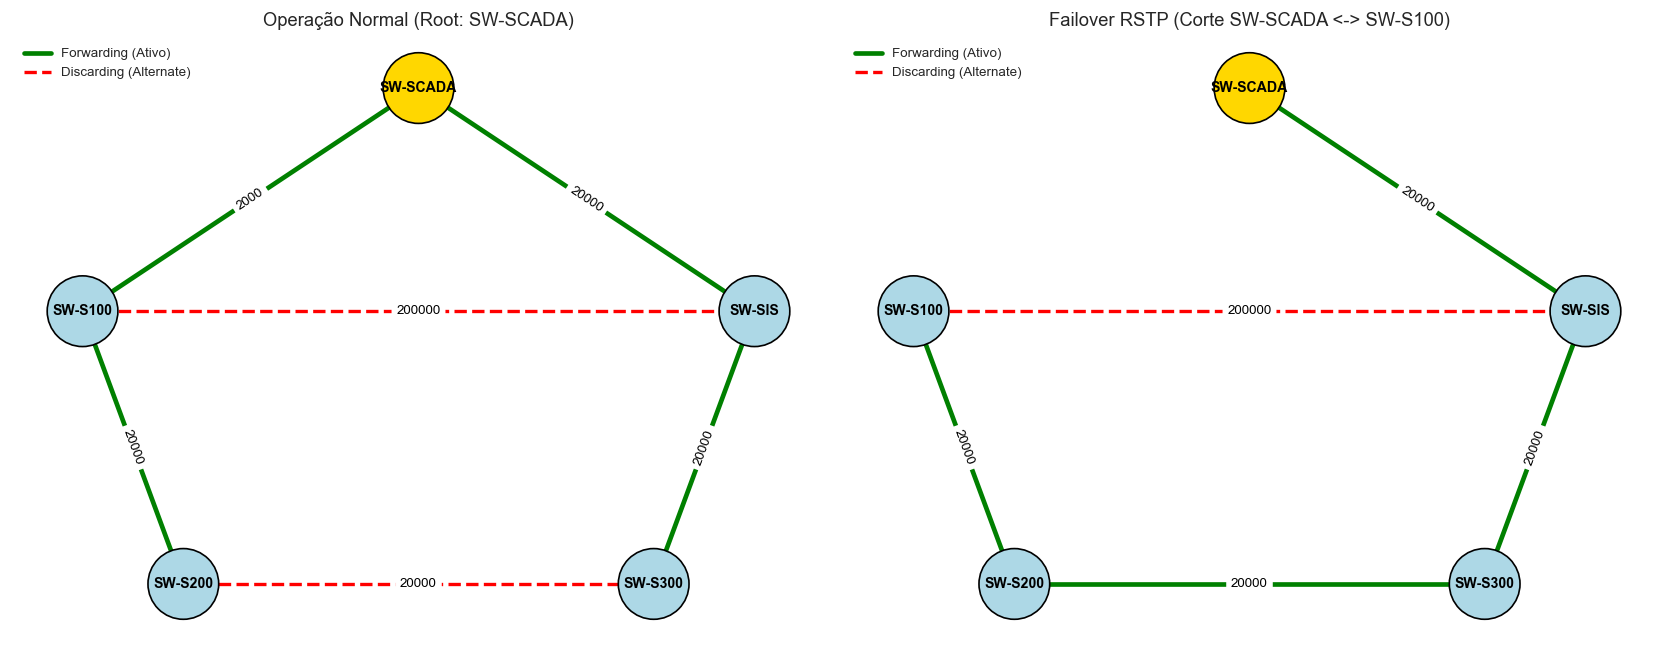

In [3]:
G_falha = G.copy()
G_falha.remove_edge("SW-SCADA", "SW-S100")
root_f, dist_f, ativas_f, bloq_f, df_f = executar_rstp(G_falha)
print(f"Pós-Failover | Custos até o Root: {dist_f}")
display(df_f)

def plot_rstp(ax, grafo, root, ativas, bloqueadas, titulo):
    pos = {"SW-SCADA": (0.5, 1.0), "SW-S100": (0.0, 0.55), "SW-SIS": (1.0, 0.55), "SW-S200": (0.15, 0.0), "SW-S300": (0.85, 0.0)}
    cores = ["gold" if n == root else "lightblue" for n in grafo.nodes]
    nx.draw_networkx_nodes(grafo, pos, ax=ax, node_color=cores, node_size=1800, edgecolors="black")
    nx.draw_networkx_labels(grafo, pos, ax=ax, font_size=8.5, font_weight="bold")
    nx.draw_networkx_edges(grafo, pos, ax=ax, edgelist=ativas, width=2.8, edge_color="green")
    nx.draw_networkx_edges(grafo, pos, ax=ax, edgelist=bloqueadas, width=2.0, style="dashed", edge_color="red")
    edge_labels = {(u, v): f"{grafo[u][v]['cost']}" for u, v in grafo.edges}
    nx.draw_networkx_edge_labels(grafo, pos, ax=ax, edge_labels=edge_labels, font_size=8)
    legenda = [
        Line2D([0], [0], color="green", lw=2.8, label="Forwarding (Ativo)"),
        Line2D([0], [0], color="red", lw=2.0, linestyle="--", label="Discarding (Alternate)"),
    ]
    ax.legend(handles=legenda, loc="upper left", fontsize=8)
    ax.set_title(titulo, fontsize=11)
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_rstp(axes[0], G, root_n, ativas_n, bloq_n, "Operação Normal (Root: SW-SCADA)")
plot_rstp(axes[1], G_falha, root_f, ativas_f, bloq_f, "Failover RSTP (Corte SW-SCADA <-> SW-S100)")
plt.tight_layout()
plt.show()

for nome, g, at in [("Normal", G, ativas_n), ("Pós-Failover", G_falha, ativas_f)]:
    T = nx.Graph()
    T.add_nodes_from(g.nodes)
    T.add_edges_from(at)
    assert nx.is_connected(T) and nx.is_forest(T) and T.number_of_edges() == g.number_of_nodes() - 1
    print(f"[{nome}] Árvore Geradora válida: conexa, acíclica e |E_T| = {T.number_of_edges()}.")